# Closing the loop: does one real patch per frame keep a world model on track?

The earlier runs only *measured* drift: the real patch the agent looked at was never shown to the model. Here it is. After each imagined frame, the one real 32×32 patch the agent inspects (1/16 of the pixels) is pasted into the rollout, so every later frame is generated with it in view. Diffusion Forcing keeps finished frames fixed in its sliding window, so the pasted patch becomes part of the model's context.

**Conditions.** The first 16 Minecraft clips of the main run (all 10 validation videos), 2 rollouts each, 50 sampling steps, compared with the main run's 3 rollouts of the same clips without feedback:

- **random gaze**: the patch is drawn uniformly;
- **guided gaze**: drawn with probability ∝ √(change of the imagined patch since the previous frame), with a 10% uniform floor. This is label-free; motion was the best single visual predictor of error;
- **oracle gaze**: the patch with the largest true error. Not deployable; an upper bound on targeting.

**Measured.**

- drift of the model's prediction of each frame, made *before* that frame's patch is shown, with and without feedback, paired by clip, with 95% CIs over videos;
- for random and guided gaze, how well the same patches *measure* the drift (Horvitz–Thompson estimate).

**Running.** Kaggle, accelerator **GPU T4 x2**, Internet on. Before running, attach the main run's output: *Add Input → Your Work → Notebooks → wm-selfaudit-full* (the 100-step notebook's output also works). Its rollouts without feedback are reused. 12 jobs, about 4 h. Then *Save Version → Save & Run All*.

## 1. Configuration

In [1]:
import os, re, subprocess, sys, time, shutil, glob, json, threading
import numpy as np

NOTEBOOK_START = time.time()
WORK = "/kaggle/working"
REPO = "/tmp/diffusion-forcing"
DUMP_ROOT = f"{WORK}/wm_audit_data"
RESULTS = f"{WORK}/wm_audit_results"
LOGS = f"{WORK}/generation_logs"
AUDIT = f"{WORK}/wm_audit.py"

N_RUNS = 3
BATCH = 8
GEN_HOURS = 10.5
EPS = 0.1

WANDB_ENTITY = "usmanajmal659-islamia-university-of-bwp"
QUICKSTART_ID = "1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b"

FEEDBACK = dict(data="minecraft", dataset="video_minecraft", ckpt="minecraft", patch=32, trained_frames=10, multiplier=2,
                frame_skip=2, per_video=4, n_clips=16, steps=50, runs=2, script="df_feedback_run.py", extra="", prior_min=40)
CONDITIONS = {
    "minecraft": dict(label="Minecraft, 50 steps", data="minecraft", dataset="video_minecraft", ckpt="minecraft",
                      patch=32, trained_frames=10, multiplier=2, frame_skip=2, per_video=4, n_clips=40, steps=50,
                      fit_on="minecraft", extra="", prior_min=40),
    "feedback_guided": dict(FEEDBACK, label="Guided gaze", gaze="guided"),
    "feedback_random": dict(FEEDBACK, label="Random gaze", gaze="random"),
    "feedback_oracle": dict(FEEDBACK, label="Oracle gaze (not deployable)", gaze="oracle"),
}
REFERENCE = "minecraft"
PRIORITY = [(n, [b]) for b in (0, 1) for n in ("feedback_guided", "feedback_random", "feedback_oracle")]


def run(cmd, cwd=None, env=None, log=None, show=None, tail=40, timeout_min=None, prefix=""):
    """Run a shell command in a fresh process; stream selected lines, keep a full log, return the exit code."""
    lines, t0 = [], time.time()
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, text=True, bufsize=1, start_new_session=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    timer = None
    if timeout_min:
        timer = threading.Timer(60 * timeout_min, lambda: (print(f"{prefix}!!! timeout after {timeout_min:.0f} min: stopping",
                                                                 flush=True), os.killpg(p.pid, 9)))
        timer.start()
    fh = open(log, "w") if log else None
    last_beat, last_progress = time.time() - 360, ""
    for line in p.stdout:
        if fh: fh.write(line)
        lines.append(line)
        if "Sampling" in line or "Validation" in line:
            last_progress = line.strip().split("\r")[-1]
        if show is None or any(s in line for s in show):
            print(prefix + line.rstrip()[:400], flush=True)
        elif time.time() - last_beat > 600:
            print(f"{prefix}[{(time.time() - t0) / 60:5.1f} min] {last_progress[:150]}", flush=True)
            last_beat = time.time()
    p.wait()
    if timer: timer.cancel()
    if fh: fh.close()
    if p.returncode != 0 and show is not None:
        print(f"{prefix}--- command failed (exit {p.returncode}); last {tail} lines ---")
        print("".join(lines[-tail:]))
    return p.returncode

print("Python", sys.version.split()[0])
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout)

Python 3.13.15
GPU 0: Tesla T4 (UUID: GPU-68b2ec23-c8a8-1710-749f-c9f2920e7972)
GPU 1: Tesla T4 (UUID: GPU-f88377d3-9188-7b2e-4915-6921018ba48a)



## 2. Setup

Clone the official Diffusion Forcing repository, install its requirements and download the pretrained checkpoints with the mini validation sets.

In [2]:
if not os.path.isdir(REPO):
    assert run(f"git clone --depth 1 https://github.com/buoyancy99/diffusion-forcing.git {REPO}") == 0
print("repository:", REPO, subprocess.run(["git", "-C", REPO, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout)

Cloning into '/tmp/diffusion-forcing'...
repository: /tmp/diffusion-forcing 475e0bc



In [3]:
marker = f"{REPO}/.df_requirements_installed"
if not os.path.exists(marker):
    reqs = [l.strip() for l in open(f"{REPO}/requirements.txt") if l.strip() and not l.strip().startswith("#")]
    failed = []
    for r in reqs:
        name = re.split(r"[<>=!~\[ ;]", r)[0].lower()
        if name in {"torch", "torchvision", "torchaudio"}:
            continue
        if subprocess.run([sys.executable, "-m", "pip", "install", "-q", r],
                          capture_output=True, text=True).returncode != 0:
            failed.append(r)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "imageio"], capture_output=True)
    open(marker, "w").write("\n".join(failed))
    print("installed; failed pins:", failed or "none")
else:
    print("requirements already installed; failed pins:", open(marker).read() or "none")

installed; failed pins: none


In [4]:
assert run(f"{sys.executable} -c \"import hydra, omegaconf, lightning, wandb, torch, numpy, scipy, imageio, matplotlib; "
           f"print('torch', torch.__version__, '| numpy', numpy.__version__, '| GPUs:', torch.cuda.device_count())\"",
           cwd=REPO) == 0

/usr/local/lib/python3.13/dist-packages/lightning/fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
torch 2.11.0+cu128 | numpy 2.5.4 | GPUs: 2


In [5]:
if not glob.glob(f"{REPO}/outputs/*.ckpt"):
    assert run(f"gdown {QUICKSTART_ID} -O quickstart_atten.tar.gz && tar -xzf quickstart_atten.tar.gz && rm quickstart_atten.tar.gz",
               cwd=REPO) == 0
ckpts = sorted(glob.glob(f"{REPO}/outputs/*.ckpt"))
print("checkpoints:", [os.path.basename(p) for p in ckpts])

for name, c in list(CONDITIONS.items()):
    c["ckpt_path"] = next((os.path.relpath(p, REPO) for p in ckpts if c["ckpt"] in os.path.basename(p).lower()), None)
    meta_path = f"{REPO}/data/{c['data']}/metadata.json"
    videos = sorted(glob.glob(f"{REPO}/data/{c['data']}/validation/**/*.npz", recursive=True))
    lengths = json.load(open(meta_path))["validation"] if os.path.exists(meta_path) else []
    problem = ("no checkpoint" if not c["ckpt_path"] else "no metadata.json" if not lengths
               else "metadata does not match the videos" if len(lengths) != len(videos) else None)
    if problem:
        print(f"{name}: {problem}, skipped")
        del CONDITIONS[name]
        continue
    c["videos"], c["length"] = len(videos), int(min(lengths))
    print(f"{name}: {c['ckpt_path']}, {len(videos)} validation videos of {c['length']} frames")
assert REFERENCE in CONDITIONS, "the Minecraft checkpoint or data is missing"

Downloading...
From (original): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b
From (redirected): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b&confirm=t&uuid=3e622ebf-40b6-4457-ae4d-0d4d5b83e2f7
To: /tmp/diffusion-forcing/quickstart_atten.tar.gz

  0%|          | 0.00/592M [00:00<?, ?B/s]
  1%|          | 6.82M/592M [00:00<00:08, 67.7MB/s]
  4%|▍         | 23.6M/592M [00:00<00:04, 117MB/s]
  7%|▋         | 40.4M/592M [00:00<00:04, 120MB/s]
 10%|█         | 59.2M/592M [00:00<00:04, 123MB/s]
 12%|█▏        | 73.9M/592M [00:00<00:04, 124MB/s]
 15%|█▍        | 86.5M/592M [00:00<00:06, 83.3MB/s]
 18%|█▊        | 106M/592M [00:00<00:04, 108MB/s]
 21%|██        | 123M/592M [00:01<00:03, 122MB/s]
 25%|██▍       | 147M/592M [00:01<00:02, 150MB/s]
 28%|██▊       | 164M/592M [00:01<00:03, 134MB/s]
 31%|███▏      | 186M/592M [00:01<00:02, 154MB/s]
 35%|███▍      | 206M/592M [00:01<00:02, 165MB/s]
 38%|███▊      | 223M/592M [00:01<00:02, 160MB/s]
 41%|████     

## 3. Code

`df_feedback_run.py` runs the repository's validation on a fixed list of clips with the repository's own sampling loop, extended by one step: after each imagined frame, one real patch is pasted into the rollout. It saves the model's prediction of every frame (made before that frame's patch is seen), the chosen patches and their probabilities. `wm_audit.py` implements the analysis, followed by its self-tests.

In [6]:
%%writefile /tmp/diffusion-forcing/df_feedback_run.py
"""Run Diffusion Forcing's `python -m main ...` on a fixed list of validation clips with closed-loop gaze: after each
imagined frame, one real patch of that frame is pasted into the rollout, so every later frame is generated with it
in view. The model's prediction of each frame (made before its patch is seen), the chosen patches and their
sampling probabilities are saved.

The sampling loop is the repository's own DiffusionForcingBase.validation_step, unchanged except for the paste."""
import json
import os
import runpy
import sys

import numpy as np

sys.path.insert(0, os.getcwd())
OUT = os.environ["DF_DUMP_FILE"]
CLIPS = json.loads(os.environ["DF_CLIPS"])
GAZE = os.environ["DF_GAZE"]
PATCH = int(os.environ.get("DF_PATCH", "32"))
EPS = float(os.environ.get("DF_GAZE_EPS", "0.1"))
os.makedirs(os.path.dirname(OUT), exist_ok=True)
if GAZE not in ("random", "guided", "oracle"):
    raise SystemExit(f"unknown gaze policy '{GAZE}'")

import torch
import torch.nn.functional as F
from tqdm import tqdm

import algorithms.diffusion_forcing.df_base as dfb
import datasets.video.base_video_dataset as bv
import utils.logging_utils as lu

_original_log = lu.log_video
_original_init = bv.BaseVideoDataset.__init__
_gen = torch.Generator().manual_seed(int(os.environ.get("DF_GAZE_SEED", "0")))
_gaze = {"gaze": [], "q": []}


def init_with_fixed_clips(self, cfg, split="training"):
    """Put the requested (video, start frame) windows first in the validation order."""
    _original_init(self, cfg, split)
    if split == "training":
        return
    first = np.concatenate([[0], self.cum_clips_per_video[:-1]])
    chosen = []
    for v, s in CLIPS:
        if v >= len(first) or s >= self.clips_per_video[v]:
            raise SystemExit(f"clip (video {v}, start {s}) is not in the {split} set")
        chosen.append(int(first[v] + s))
    taken = set(chosen)
    self.idx_remap = chosen + [i for i in self.idx_remap if i not in taken]


def patch_means(x):
    """(B, C, H, W) -> (B, J): mean over each P x P patch and the channels."""
    B, C, H, W = x.shape
    return x.reshape(B, C, H // PATCH, PATCH, W // PATCH, PATCH).mean(dim=(1, 3, 5)).reshape(B, -1)


def choose(prev, cur, real):
    """Pick one patch per clip, using only the imagined frames (except the oracle). Returns indices and probabilities."""
    B = cur.shape[0]
    J = (cur.shape[-2] // PATCH) * (cur.shape[-1] // PATCH)
    if GAZE == "oracle":
        return patch_means((cur - real).float() ** 2).argmax(1).cpu(), torch.ones(B)
    if GAZE == "random":
        q = torch.full((B, J), 1.0 / J)
    else:
        s = patch_means((cur - prev).float() ** 2).sqrt().cpu() + 1e-12
        q = (1 - EPS) * s / s.sum(1, keepdim=True) + EPS / J
    j = torch.multinomial(q, 1, generator=_gen).squeeze(1)
    return j, q.gather(1, j[:, None]).squeeze(1)


@torch.no_grad()
def validation_step_with_gaze(self, batch, batch_idx, namespace="validation"):
    if self.frame_stack != 1:
        raise SystemExit("closed-loop gaze assumes frame_stack == 1")
    xs, conditions, masks = self._preprocess_batch(batch)
    n_frames, batch_size, *_ = xs.shape
    curr_frame = 0

    n_context_frames = self.context_frames // self.frame_stack
    xs_pred = xs[:n_context_frames].clone()
    curr_frame += n_context_frames
    imagined = []

    pbar = tqdm(total=n_frames, initial=curr_frame, desc="Sampling")
    while curr_frame < n_frames:
        if self.chunk_size > 0:
            horizon = min(n_frames - curr_frame, self.chunk_size)
        else:
            horizon = n_frames - curr_frame
        assert horizon <= self.n_tokens, "horizon exceeds the number of tokens."
        scheduling_matrix = self._generate_scheduling_matrix(horizon)

        chunk = torch.randn((horizon, batch_size, *self.x_stacked_shape), device=self.device)
        chunk = torch.clamp(chunk, -self.clip_noise, self.clip_noise)
        xs_pred = torch.cat([xs_pred, chunk], 0)

        start_frame = max(0, curr_frame + horizon - self.n_tokens)
        pbar.set_postfix({"start": start_frame, "end": curr_frame + horizon})

        for m in range(scheduling_matrix.shape[0] - 1):
            from_noise_levels = np.concatenate((np.zeros((curr_frame,), dtype=np.int64), scheduling_matrix[m]))[
                :, None
            ].repeat(batch_size, axis=1)
            to_noise_levels = np.concatenate(
                (np.zeros((curr_frame,), dtype=np.int64), scheduling_matrix[m + 1])
            )[:, None].repeat(batch_size, axis=1)
            from_noise_levels = torch.from_numpy(from_noise_levels).to(self.device)
            to_noise_levels = torch.from_numpy(to_noise_levels).to(self.device)
            xs_pred[start_frame:] = self.diffusion_model.sample_step(
                xs_pred[start_frame:],
                conditions[start_frame : curr_frame + horizon],
                from_noise_levels[start_frame:],
                to_noise_levels[start_frame:],
            )

        # closed loop: keep the model's prediction, then show it one real patch of each new frame
        w = xs.shape[-1] // PATCH
        for f in range(curr_frame, curr_frame + horizon):
            imagined.append(xs_pred[f].clone())
            j, q = choose(xs_pred[f - 1], xs_pred[f], xs[f])
            for b in range(batch_size):
                r, c = divmod(int(j[b]), w)
                rows, cols = slice(r * PATCH, (r + 1) * PATCH), slice(c * PATCH, (c + 1) * PATCH)
                xs_pred[f, b, :, rows, cols] = xs[f, b, :, rows, cols]
            _gaze["gaze"].append(j.numpy())
            _gaze["q"].append(q.numpy())

        curr_frame += horizon
        pbar.update(horizon)

    out = torch.cat([xs_pred[:n_context_frames], torch.stack(imagined)], 0)
    loss = F.mse_loss(out, xs, reduction="none")
    loss = self.reweight_loss(loss, masks)

    xs = self._unstack_and_unnormalize(xs)
    out = self._unstack_and_unnormalize(out)
    self.validation_step_outputs.append((out.detach().cpu(), xs.detach().cpu()))
    return loss


def _to_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().float().cpu().numpy()
    return np.asarray(x, dtype=np.float32)


def log_video_and_dump(*args, **kwargs):
    named = [kwargs.get("observation_hat"), kwargs.get("observation_gt")]
    arrays = [a for a in list(args) + named if a is not None and len(getattr(a, "shape", ())) == 5]
    if len(arrays) >= 2 and not os.path.exists(OUT):
        pred, gt = _to_numpy(arrays[0]), _to_numpy(arrays[1])
        tmp = OUT[:-4] + ".part.npz"
        np.savez_compressed(tmp, pred=pred.astype(np.float16), gt=gt.astype(np.float16),
                            clips=np.array(CLIPS[:pred.shape[1]], dtype=np.int64),
                            gaze=np.stack(_gaze["gaze"]).astype(np.int16), q=np.stack(_gaze["q"]).astype(np.float32))
        os.replace(tmp, OUT)
        print(f"[dump] saved {OUT} with shape {pred.shape}, gaze '{GAZE}'", flush=True)
    return _original_log(*args, **kwargs)


bv.BaseVideoDataset.__init__ = init_with_fixed_clips
dfb.DiffusionForcingBase.validation_step = validation_step_with_gaze
lu.log_video = log_video_and_dump
# importing df_base already imported df_video, which holds its own reference to the original logger
for mod in list(sys.modules.values()):
    if getattr(mod, "log_video", None) is _original_log:
        mod.log_video = log_video_and_dump
sys.argv = ["main.py"] + sys.argv[1:]
runpy.run_module("main", run_name="__main__", alter_sys=True)
if not os.path.exists(OUT):
    raise SystemExit(f"validation finished but nothing was saved to {OUT}")

Writing /tmp/diffusion-forcing/df_feedback_run.py


In [7]:
%%writefile /kaggle/working/wm_audit.py
"""Self-auditing a video world model with sparse real observations."""
import argparse
import glob
import json
import os

import numpy as np

FEATURES_VISUAL = ["texture", "motion", "time"]
FEATURES_ALL = ["disagreement", "texture", "motion", "time"]
FEATURES_PAIR = ["disagreement_pair", "texture", "motion", "time"]

BASE = "Uniform (Horvitz-Thompson)"
VISUAL = "Smart + CV[visual]"
BEST = "Smart + CV[visual+disagreement]"
PAIR = "Smart + CV[visual+disagreement], 2 rollouts"
ORACLE = "Oracle Neyman (not deployable)"
SELF_DIS = "Rollout disagreement"
SELF_CAL = "Calibrated predictor (visual+disagreement)"
SELF_VIS = "Visual predictor"
BIN_LABELS = {"all": "all imagined frames", "within": "within trained length", "beyond": "beyond trained length"}


def to_thwc(a):
    """Dumps are (time, batch, channel, height, width); return (batch, time, height, width, channel) in [0, 1]."""
    return np.clip(np.asarray(a, np.float32).transpose(1, 0, 3, 4, 2), 0.0, 1.0)


def load_condition(cdir):
    """Clips of one condition that exist in every run: dict(video, start, gt, preds)."""
    rdirs = sorted(glob.glob(os.path.join(cdir, "run_*")))
    have = [{os.path.basename(f) for f in glob.glob(os.path.join(r, "batch_*.npz"))} for r in rdirs]
    rdirs, have = [r for r, h in zip(rdirs, have) if h], [h for h in have if h]
    if not rdirs:
        return [], 0, 0
    clips, dropped = [], 0
    for name in sorted(set.intersection(*have)):
        zs = [np.load(os.path.join(r, name)) for r in rdirs]
        gts = [to_thwc(z["gt"]) for z in zs]
        preds = [to_thwc(z["pred"]) for z in zs]
        ids = zs[0]["clips"]
        for i in range(gts[0].shape[0]):
            g = gts[0][i]
            if any(float(((g - x[i]) ** 2).mean()) > 1e-5 for x in gts[1:]):
                raise SystemExit(f"{cdir}/{name}: clip {i} has a different real video in different runs")
            if (g.reshape(g.shape[0], -1).max(1) == 0).any():
                dropped += 1
                continue
            extra = {k: [z[k][:, i] for z in zs] for k in zs[0].files if k not in ("pred", "gt", "clips")}
            clips.append(dict(video=int(ids[i][0]), start=int(ids[i][1]), gt=g, preds=[p[i] for p in preds], extra=extra))
    return clips, len(rdirs), dropped


def context_frames(clips, tol=1e-6):
    """Number of leading frames copied from the real video (prediction == real) in every clip/run."""
    n = min(c["gt"].shape[0] for c in clips)
    for t in range(n):
        for c in clips:
            for p in c["preds"]:
                if float(((p[t] - c["gt"][t]) ** 2).mean()) > tol:
                    return t
    return n


def patchify(x, P):
    T, H, W, C = x.shape
    H2, W2 = (H // P) * P, (W // P) * P
    x = x[:, :H2, :W2]
    return x.reshape(T, H2 // P, P, W2 // P, P, C).transpose(0, 1, 3, 2, 4, 5).reshape(T, (H2 // P) * (W2 // P), -1)


def build_units(clips, P, n_ctx):
    """One unit = (clip, run). Arrays over imagined frames t >= n_ctx: e[t,j] true patch error, label-free features."""
    units = []
    R = len(clips[0]["preds"])
    for ci, c in enumerate(clips):
        gt_p = patchify(c["gt"], P)
        pr_p = [patchify(p, P) for p in c["preds"]]
        T, J = gt_p.shape[:2]
        tt = np.repeat(((np.arange(T) - n_ctx + 1) / max(T - n_ctx, 1))[:, None], J, 1)
        sl = slice(n_ctx, T)
        for r in range(R):
            g = pr_p[r]
            mot = np.zeros((T, J), np.float32)
            mot[1:] = ((g[1:] - g[:-1]) ** 2).mean(-1)
            f = dict(texture=g.var(-1), motion=mot, time=tt)
            if R > 1:
                f["disagreement"] = np.mean([((g - pr_p[s]) ** 2).mean(-1) for s in range(R) if s != r], axis=0)
                f["disagreement_pair"] = ((g - pr_p[(r + 1) % R]) ** 2).mean(-1)
            e = ((g - gt_p) ** 2).mean(-1)
            units.append(dict(clip=ci, run=r, video=c["video"], e=e[sl].astype(np.float64),
                              f={k: np.asarray(v[sl], np.float64) for k, v in f.items()}))
    return units


def design(u, names):
    cols = [u["f"][n].ravel() for n in names] + [np.ones(u["e"].size)]
    return np.stack(cols, 1)


def fit_models(train, names, ridge=1e-8):
    """Least-squares mean model for e, and a second-moment model for the residual (for sampling)."""
    X = np.concatenate([design(u, names) for u in train])
    y = np.concatenate([u["e"].ravel() for u in train])
    sc = X.std(0)
    sc[sc == 0] = 1.0
    Xs = X / sc
    A = Xs.T @ Xs + ridge * np.eye(Xs.shape[1])
    w = np.linalg.solve(A, Xs.T @ y) / sc
    r2 = (y - X @ w) ** 2
    v = np.linalg.solve(A, Xs.T @ r2) / sc
    return w, v


def frame_estimates(e_t, mu_t, q_t):
    """All J possible single-patch estimates of the frame-mean error at one frame."""
    J = e_t.size
    return mu_t.mean() + (e_t - mu_t) / (J * q_t)


def exact_relvar(e, mu, q, k=1):
    """Exact relative variance of the rollout-mean estimate with k independent patches per frame."""
    T = e.shape[0]
    var = 0.0
    for t in range(T):
        est = frame_estimates(e[t], mu[t], q[t])
        var += float((q[t] * (est - e[t].mean()) ** 2).sum())
    var /= (k * T * T)
    return var / float(e.mean()) ** 2


def exact_bias(e, mu, q):
    out = 0.0
    for t in range(e.shape[0]):
        out += float((q[t] * frame_estimates(e[t], mu[t], q[t])).sum() - e[t].mean())
    return out / e.shape[0]


def sampling_from_m2(m2, eps):
    s = np.sqrt(np.clip(m2, 1e-12, None))
    q = s / s.sum(1, keepdims=True)
    return (1 - eps) * q + eps / q.shape[1]


def shuffle_within_frames(u, names, rng):
    perm = np.argsort(rng.random(u["e"].shape), axis=1)
    return dict(e=u["e"], f={n: np.take_along_axis(u["f"][n], perm, 1) for n in names})


def method_plan(units, pool, eps, seed=0):
    """(mu, q) of every audit and the label-free self-assessments, for every unit.
    Predictors are fit on `pool` leaving out every unit of the test unit's video."""
    rng = np.random.default_rng(seed)
    feats = {"visual": FEATURES_VISUAL}
    if "disagreement" in units[0]["f"] and "disagreement" in pool[0]["f"]:
        feats["all"] = FEATURES_ALL
        if 1 + max(u["run"] for u in units) > 2 and "disagreement_pair" in pool[0]["f"]:
            feats["pair"] = FEATURES_PAIR
    plans, selfs = {}, {}
    for v in sorted({u["video"] for u in units}):
        train = [u for u in pool if u["video"] != v]
        if not train:
            raise SystemExit("Leave-one-video-out fitting needs clips from at least 2 videos.")
        models = {k: fit_models(train, names) for k, names in feats.items()}
        models["shuffled"] = fit_models([shuffle_within_frames(u, FEATURES_VISUAL, rng) for u in train], FEATURES_VISUAL)
        for u in units:
            if u["video"] != v:
                continue
            shp = u["e"].shape
            uni = np.full(shp, 1.0 / shp[1])
            mu, m2 = {}, {}
            for k, (w, s) in models.items():
                src = shuffle_within_frames(u, FEATURES_VISUAL, rng) if k == "shuffled" else u
                X = design(src, feats.get(k, FEATURES_VISUAL))
                mu[k], m2[k] = (X @ w).reshape(shp), (X @ s).reshape(shp)
            p = {BASE: (np.zeros(shp), uni),
                 "Uniform + CV[visual]": (mu["visual"], uni),
                 VISUAL: (mu["visual"], sampling_from_m2(m2["visual"], eps)),
                 "Negative control: CV[shuffled proxies]": (mu["shuffled"], uni)}
            sa = {SELF_VIS: mu["visual"]}
            if "all" in mu:
                p["Uniform + CV[visual+disagreement]"] = (mu["all"], uni)
                p[BEST] = (mu["all"], sampling_from_m2(m2["all"], eps))
                if "pair" in mu:
                    p[PAIR] = (mu["pair"], sampling_from_m2(m2["pair"], eps))
                sa[SELF_DIS] = u["f"]["disagreement"]
                sa[SELF_CAL] = mu["all"]
            best = mu.get("all", mu["visual"])
            p[ORACLE] = (best, sampling_from_m2((u["e"] - best) ** 2, eps))
            plans[(u["clip"], u["run"])] = p
            selfs[(u["clip"], u["run"])] = sa
    return plans, selfs


def horizon_bins(n_eval, n_inside):
    bins = {"all": slice(0, n_eval)}
    if 0 < n_inside < n_eval:
        bins["within"] = slice(0, n_inside)
        bins["beyond"] = slice(n_inside, n_eval)
    return bins


def evaluate(units, plans, selfs, sl):
    """Exact relative variance and bias of every audit, and relative error of every self-assessment, on frames `sl`."""
    n = len(units)
    rv, bias, se = {}, {}, {}
    for i, u in enumerate(units):
        key = (u["clip"], u["run"])
        e = u["e"][sl]
        truth = float(e.mean())
        for m, (mu, q) in plans[key].items():
            rv.setdefault(m, np.zeros(n))[i] = exact_relvar(e, mu[sl], q[sl])
            bias[m] = max(bias.get(m, 0.0), abs(exact_bias(e, mu[sl], q[sl])) / truth)
        for m, est in selfs[key].items():
            se.setdefault(m, np.zeros(n))[i] = (float(est[sl].mean()) - truth) / truth
    return dict(rv=rv, bias=bias, self_err=se)


def cluster_sets(groups, B=5000, seed=1):
    """Bootstrap resamples of whole videos: windows of one video are not independent."""
    rng = np.random.default_rng(seed)
    g = np.asarray(groups)
    members = [np.flatnonzero(g == k) for k in np.unique(g)]
    return [np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))]) for _ in range(B)]


def ci(stat, sets):
    s = np.array([stat(x) for x in sets])
    return float(np.quantile(s, 0.025)), float(np.quantile(s, 0.975))


def audit_rows(ev, sets, k=1):
    rv, n = ev["rv"], len(next(iter(ev["rv"].values())))
    full = np.arange(n)
    rows = []
    for m in rv:
        rel = lambda s, m=m: 100 * np.sqrt(rv[m][s].mean() / k)
        ratio = lambda s, m=m: rv[m][s].mean() / rv[BASE][s].mean()
        lo, hi = ci(rel, sets)
        rlo, rhi = ci(ratio, sets)
        r = ratio(full)
        rows.append(dict(method=m, rel_rmse_pct=rel(full), ci_lo=lo, ci_hi=hi, var_ratio=r, ratio_lo=rlo,
                         ratio_hi=rhi, budget_equiv=1 / r, max_abs_bias_pct=100 * ev["bias"][m]))
    return rows


def self_rows(ev, sets):
    rows = []
    for m, err in ev["self_err"].items():
        full = np.arange(len(err))
        bias = lambda s, err=err: 100 * err[s].mean()
        rmse = lambda s, err=err: 100 * np.sqrt((err[s] ** 2).mean())
        blo, bhi = ci(bias, sets)
        lo, hi = ci(rmse, sets)
        rows.append(dict(method=m, bias_pct=bias(full), bias_lo=blo, bias_hi=bhi, rel_rmse_pct=rmse(full),
                         ci_lo=lo, ci_hi=hi))
    return rows


def calibration(units, sl, sets):
    """How well the model's own disagreement matches its real error: slope of error on disagreement through the origin."""
    from scipy.stats import spearmanr
    E = [u["e"][sl] for u in units]
    D = [u["f"]["disagreement"][sl] for u in units]
    sED = np.array([(e * d).sum() for e, d in zip(E, D)])
    sDD = np.array([(d * d).sum() for d in D])
    sE, sD = np.array([e.sum() for e in E]), np.array([d.sum() for d in D])
    slope = lambda s: sED[s].sum() / sDD[s].sum()
    ratio = lambda s: sE[s].sum() / sD[s].sum()
    full = np.arange(len(units))
    lo, hi = ci(slope, sets)
    rlo, rhi = ci(ratio, sets)
    rho = float(spearmanr(np.concatenate([e.ravel() for e in E]), np.concatenate([d.ravel() for d in D]))[0])
    return dict(slope=float(slope(full)), slope_lo=lo, slope_hi=hi, error_over_disagreement=float(ratio(full)),
                ratio_lo=rlo, ratio_hi=rhi, spearman=rho)


def compute_frontier(ev, sets, ks=(1, 2, 3, 4)):
    """Real patches per frame versus extra rollouts: what each costs and what it buys."""
    rv = ev["rv"]
    lines = [("1 rollout, uniform", BASE, 1), ("1 rollout, smart + CV[visual]", VISUAL, 1),
             ("2 rollouts, smart + CV[visual+disagreement]", PAIR, 2),
             ("3 rollouts, smart + CV[visual+disagreement]", BEST, 3)]
    full = np.arange(len(rv[BASE]))
    out = []
    for label, m, nroll in lines:
        if m not in rv:
            continue
        for k in ks:
            rel = lambda s, m=m, k=k: 100 * np.sqrt(rv[m][s].mean() / k)
            lo, hi = ci(rel, sets)
            out.append(dict(config=label, method=m, rollouts=nroll, patches=k, rel_rmse_pct=rel(full), ci_lo=lo, ci_hi=hi))
    head = {}
    if BEST in rv:
        eq = lambda s: rv[VISUAL][s].mean() / rv[BEST][s].mean()
        lo, hi = ci(eq, sets)
        head["patches_equiv_3_rollouts"] = dict(value=float(eq(full)), ci_lo=lo, ci_hi=hi)
        r = lambda s: rv[BEST][s].mean() / (rv[VISUAL][s].mean() / 2)
        lo, hi = ci(r, sets)
        head["var_3r1p_over_1r2p"] = dict(value=float(r(full)), ci_lo=lo, ci_hi=hi)
    return out, head


def mc_check(u, plan, rng, reps=2000):
    out = {}
    Tn, Jn = u["e"].shape
    truth = u["e"].mean()
    for m, (mu, q) in plan.items():
        est = np.zeros(reps)
        for t in range(Tn):
            est += frame_estimates(u["e"][t], mu[t], q[t])[rng.choice(Jn, size=reps, p=q[t])]
        est /= Tn
        out[m] = dict(mc_bias_pct=float(100 * (est.mean() - truth) / truth),
                      mc_relrmse_pct=float(100 * np.sqrt(((est - truth) ** 2).mean()) / truth),
                      exact_relrmse_pct=float(100 * np.sqrt(exact_relvar(u["e"], mu, q))))
    return out


def md_table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    return "\n".join(lines)


def analyze(data_root, out, eps=0.1, mc_reps=2000, B=5000):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    ref = plan["reference"]
    conds = {}
    for name, cfg in plan["conditions"].items():
        clips, R, dropped = load_condition(os.path.join(data_root, name))
        n_videos = len({c["video"] for c in clips})
        if n_videos < 3:
            print(f"{name}: {len(clips)} clips from {n_videos} videos; need at least 3 videos, skipped")
            continue
        n_ctx = context_frames(clips)
        T, H, W, _ = clips[0]["gt"].shape
        P = cfg["patch"]
        units = build_units(clips, P, n_ctx)
        conds[name] = dict(cfg=cfg, clips=clips, units=units, R=R, n_ctx=n_ctx, T=T, H=H, W=W, P=P,
                           J=(H // P) * (W // P), videos=n_videos,
                           bins=horizon_bins(T - n_ctx, cfg["trained_frames"] - n_ctx))
        print(f"{name}: {len(clips)} clips from {n_videos} videos x {R} runs, {T} frames ({n_ctx} context), "
              f"{H}x{W}, patch {P} -> J={conds[name]['J']}" + (f", {dropped} padded clips dropped" if dropped else ""))
    if ref not in conds:
        raise SystemExit(f"The reference condition '{ref}' has no usable data.")

    report, summary = [], dict(eps=eps, conditions={})
    for name, c in conds.items():
        fit_on = c["cfg"].get("fit_on", name)
        if fit_on not in conds:
            print(f"{name}: predictors are fit on '{fit_on}', which has no data; skipped")
            continue
        units = c["units"]
        pool = conds[fit_on]["units"]
        c["plans"], c["selfs"] = method_plan(units, pool, eps)
        sets = cluster_sets([u["video"] for u in units], B=B)
        c["ev"] = {b: evaluate(units, c["plans"], c["selfs"], sl) for b, sl in c["bins"].items()}
        s = dict(label=c["cfg"]["label"], fit_on=fit_on, clips=len(c["clips"]), videos=c["videos"], runs=c["R"],
                 frames=c["T"], context=c["n_ctx"], patch=c["P"], patches_per_frame=c["J"],
                 bins={b: [sl.start + 1, sl.stop] for b, sl in c["bins"].items()},
                 audits={b: audit_rows(ev, sets) for b, ev in c["ev"].items()},
                 self_assessment={b: self_rows(ev, sets) for b, ev in c["ev"].items()})
        if c["R"] > 1:
            s["calibration"] = {b: calibration(units, sl, sets) for b, sl in c["bins"].items()}
            Eall = np.concatenate([u["e"].ravel() for u in units])
            from scipy.stats import spearmanr
            s["proxy_spearman"] = {n: float(spearmanr(Eall, np.concatenate([u["f"][n].ravel() for u in units]))[0])
                                   for n in FEATURES_ALL}
        if c["R"] > 2:
            s["compute"], s["compute_headline"] = compute_frontier(c["ev"]["all"], sets)
        drift = np.array([[((p - x["gt"]) ** 2).mean(axis=(1, 2, 3)) for p in x["preds"]] for x in c["clips"]])
        s["drift_mean_per_frame"] = drift.mean(axis=(0, 1)).tolist()
        c["drift"] = drift
        if c["R"] > 1:
            c["dis_curve"] = np.array([[np.mean([((x["preds"][r] - x["preds"][q]) ** 2).mean(axis=(1, 2, 3))
                                                 for q in range(c["R"]) if q != r], axis=0) for r in range(c["R"])]
                                       for x in c["clips"]])
        if name == ref:
            u0 = units[0]
            s["mc_check"] = mc_check(u0, c["plans"][(u0["clip"], u0["run"])], np.random.default_rng(7), mc_reps)
        summary["conditions"][name] = s
    done = [n for n in conds if "ev" in conds[n]]

    for name in done:
        c, s = conds[name], summary["conditions"][name]
        rows = s["audits"]["all"]
        report.append(f"## {s['label']}\n\n{s['clips']} clips from {s['videos']} videos x {s['runs']} rollouts; "
                      f"{s['frames'] - s['context']} imagined frames after {s['context']} real context frames; "
                      f"{s['patches_per_frame']} patches per frame, 1 inspected. Predictors fit on "
                      f"'{conds[s['fit_on']]['cfg']['label']}', leaving the evaluated video out. "
                      f"95% CIs resample whole videos.\n")
        report.append(md_table(["Audit (1 real patch per frame)", "Relative error (%)", "95% CI", "Variance vs uniform",
                                "95% CI", "Equivalent budget", "Max bias (%)"],
                               [[r["method"], f"{r['rel_rmse_pct']:.1f}", f"{r['ci_lo']:.1f}-{r['ci_hi']:.1f}",
                                 f"{r['var_ratio']:.2f}", f"{r['ratio_lo']:.2f}-{r['ratio_hi']:.2f}",
                                 f"x{r['budget_equiv']:.2f}", f"{r['max_abs_bias_pct']:.1e}"] for r in rows]) + "\n")
        sr = []
        for b in c["bins"]:
            best = next((r for r in s["audits"][b] if r["method"] == BEST),
                        next(r for r in s["audits"][b] if r["method"] == VISUAL))
            for r in s["self_assessment"][b]:
                sr.append([BIN_LABELS[b], r["method"] + " (no real data)", f"{r['bias_pct']:+.1f} ({r['bias_lo']:+.1f} to {r['bias_hi']:+.1f})",
                           f"{r['rel_rmse_pct']:.1f} ({r['ci_lo']:.1f}-{r['ci_hi']:.1f})"])
            sr.append([BIN_LABELS[b], f"Audit: {best['method']}, 1 patch", "0 (exact)",
                       f"{best['rel_rmse_pct']:.1f} ({best['ci_lo']:.1f}-{best['ci_hi']:.1f})"])
        report.append("**Self-assessment versus audit**\n\n" + md_table(
            ["Frames", "Estimator", "Signed bias (%) [95% CI]", "Relative error (%) [95% CI]"], sr) + "\n")
        if "calibration" in s:
            report.append("**Calibration of the model's disagreement** (mean real error / mean disagreement: "
                          "1 = calibrated, >1 = over-confident; the slope through the origin is dominated by the few "
                          "patches with large disagreement)\n\n" + md_table(
                ["Frames", "Mean error / mean disagreement", "95% CI", "Slope", "95% CI", "Spearman"],
                [[BIN_LABELS[b], f"{k['error_over_disagreement']:.2f}", f"{k['ratio_lo']:.2f}-{k['ratio_hi']:.2f}",
                  f"{k['slope']:.2f}", f"{k['slope_lo']:.2f}-{k['slope_hi']:.2f}", f"{k['spearman']:.2f}"]
                 for b, k in s["calibration"].items()]) + "\n")
        if "compute" in s:
            ks = sorted({r["patches"] for r in s["compute"]})
            cfgs = list(dict.fromkeys(r["config"] for r in s["compute"]))
            report.append("**Rollouts versus real patches** (relative error %, all imagined frames)\n\n" + md_table(
                ["Configuration"] + [f"{k} patch{'es' if k > 1 else ''}/frame" for k in ks],
                [[cf] + [next(f"{r['rel_rmse_pct']:.1f} ({r['ci_lo']:.1f}-{r['ci_hi']:.1f})" for r in s["compute"]
                              if r["config"] == cf and r["patches"] == k) for k in ks] for cf in cfgs]) + "\n")
        report.append("")

    rs = summary["conditions"][ref]
    notes = []
    for r in rs["audits"]["all"]:
        if r["method"] in (BASE, ORACLE):
            continue
        notes.append(f"- **{r['method']}**: variance x{r['var_ratio']:.2f} of uniform (95% CI {r['ratio_lo']:.2f}-"
                     f"{r['ratio_hi']:.2f}), the accuracy of {r['budget_equiv']:.2f} uniform patches per frame. "
                     + ("Reduction is statistically clear." if r["ratio_hi"] < 1 else "Not distinguishable from uniform."))
    if "compute_headline" in rs and rs["compute_headline"]:
        h = rs["compute_headline"]
        e, v = h["patches_equiv_3_rollouts"], h["var_3r1p_over_1r2p"]
        notes.append(f"- **Rollouts versus patches**: with 3 rollouts and 1 patch per frame the audit is as accurate as a "
                     f"single-rollout audit with {e['value']:.2f} patches per frame (95% CI {e['ci_lo']:.2f}-{e['ci_hi']:.2f}). "
                     f"Variance of 3 rollouts + 1 patch relative to 1 rollout + 2 patches: {v['value']:.2f} "
                     f"({v['ci_lo']:.2f}-{v['ci_hi']:.2f}).")
    for name in done:
        s = summary["conditions"][name]
        for b, rows in s["self_assessment"].items():
            for r in rows:
                if r["method"] == SELF_VIS:
                    continue
                sig = r["bias_hi"] < 0 or r["bias_lo"] > 0
                notes.append(f"- **{s['label']}, {BIN_LABELS[b]}, {r['method']}**: bias {r['bias_pct']:+.1f}% "
                             f"({r['bias_lo']:+.1f} to {r['bias_hi']:+.1f}), "
                             + ("CI excludes zero." if sig else "CI includes zero."))
    notes.append("- **Unbiasedness**: the exact expectation of every audit equals the truth to numerical precision "
                 "(max bias column), in every condition and horizon, including the negative control.")
    md = "\n".join(report) + "\n## Findings\n\n" + "\n".join(notes) + "\n"
    open(os.path.join(out, "results.md"), "w").write(md)
    json.dump(summary, open(os.path.join(out, "summary.json"), "w"), indent=2)
    with open(os.path.join(out, "per_unit.csv"), "w") as f:
        f.write("condition,frames,estimator,clip,run,video,start,relative_variance,relative_error\n")
        for name in done:
            c = conds[name]
            for b, ev in c["ev"].items():
                for i, u in enumerate(c["units"]):
                    st = c["clips"][u["clip"]]["start"]
                    for m, v in ev["rv"].items():
                        f.write(f"{name},{b},{m},{u['clip']},{u['run']},{u['video']},{st},{v[i]:.6g},\n")
                    for m, v in ev["self_err"].items():
                        f.write(f"{name},{b},{m},{u['clip']},{u['run']},{u['video']},{st},,{v[i]:.6g}\n")

    fig, axs = plt.subplots(1, len(done), figsize=(5.2 * len(done), 3.8), squeeze=False)
    for a, name in zip(axs[0], done):
        c = conds[name]
        T, n_ctx, C = c["T"], c["n_ctx"], len(c["clips"])
        tt = np.arange(T) - n_ctx + 1
        for row in c["drift"].reshape(-1, T):
            a.plot(tt, row, color="0.8", lw=0.6)
        vids = np.array([x["video"] for x in c["clips"]])
        sets = cluster_sets(vids, B=1000, seed=3)
        boot = np.array([c["drift"][s].mean(axis=(0, 1)) for s in sets])
        a.plot(tt, c["drift"].mean(axis=(0, 1)), color="C0", lw=2.2, label=f"real error, {C} clips x {c['R']} rollouts")
        a.fill_between(tt, np.quantile(boot, .025, 0), np.quantile(boot, .975, 0), color="C0", alpha=.25)
        if "dis_curve" in c:
            a.plot(tt, c["dis_curve"].mean(axis=(0, 1)), "--", color="C3", lw=2, label="model's own disagreement")
        a.axvline(0.5, color="k", ls=":", lw=1)
        if "beyond" in c["bins"]:
            a.axvline(c["bins"]["beyond"].start + 0.5, color="0.4", ls="--", lw=1, label="trained sequence length")
        a.set_title(c["cfg"]["label"], fontsize=10)
        a.set_xlabel("frames after the last real context frame")
        a.grid(alpha=.3)
        a.legend(fontsize=7)
    axs[0][0].set_ylabel("full-frame MSE")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig1_drift.png"), dpi=150)
    plt.close(fig)

    with_cal = [n for n in done if "calibration" in summary["conditions"][n]]
    if with_cal:
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
        units = conds[ref]["units"]
        E = np.concatenate([u["e"].ravel() for u in units])
        D = np.concatenate([u["f"]["disagreement"].ravel() for u in units])
        edges = np.quantile(D, np.linspace(0, 1, 11))
        idx = np.clip(np.digitize(D, edges[1:-1]), 0, 9)
        a1.scatter(D, E, s=2, alpha=.1, color="0.5", label="patches")
        a1.plot([D[idx == b].mean() for b in range(10)], [E[idx == b].mean() for b in range(10)], "o-", color="C3",
                label="binned mean")
        lim = [0, float(max(np.quantile(D, .99), np.quantile(E, .99)))]
        a1.plot(lim, lim, "k--", lw=1, label="calibrated (y = x)")
        a1.set_xlim(lim)
        a1.set_ylim(lim)
        a1.set_xlabel("disagreement between rollouts (label-free)")
        a1.set_ylabel("true patch error")
        a1.set_title(f"{conds[ref]['cfg']['label']} (Spearman {summary['conditions'][ref]['calibration']['all']['spearman']:.2f})",
                     fontsize=10)
        a1.legend(fontsize=7)
        a1.grid(alpha=.3)
        x, labels = 0, []
        for i, name in enumerate(with_cal):
            for b, k in summary["conditions"][name]["calibration"].items():
                r = k["error_over_disagreement"]
                a2.errorbar(x, r, yerr=[[r - k["ratio_lo"]], [k["ratio_hi"] - r]], fmt="o", color=f"C{i}", capsize=3)
                labels.append(f"{conds[name]['cfg']['label']}\n{BIN_LABELS[b]}")
                x += 1
        a2.axhline(1, color="k", ls="--", lw=1)
        a2.set_xticks(range(x), labels, fontsize=7, rotation=30, ha="right")
        a2.set_ylabel("mean real error / mean disagreement")
        a2.set_title("1 = calibrated, above 1 = over-confident", fontsize=10)
        a2.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig2_calibration.png"), dpi=150)
        plt.close(fig)

    rows = rs["audits"]["all"]
    order = [r for r in rows if r["method"] != ORACLE] + [r for r in rows if r["method"] == ORACLE]
    fig, ax = plt.subplots(figsize=(8, 0.5 + 0.5 * len(order)))
    y = np.arange(len(order))[::-1]
    for yi, r in zip(y, order):
        col = "0.6" if r["method"].startswith(("Oracle", "Negative")) else ("C3" if "disagreement" in r["method"] else "C0")
        ax.barh(yi, r["rel_rmse_pct"], color=col)
        ax.errorbar(r["rel_rmse_pct"], yi, xerr=[[r["rel_rmse_pct"] - r["ci_lo"]], [r["ci_hi"] - r["rel_rmse_pct"]]],
                    color="k", capsize=3)
    ax.set_yticks(y, [r["method"] for r in order], fontsize=8)
    ax.set_xlabel("relative error of the drift audit (%), 1 patch per frame; lower is better")
    ax.set_title(f"{rs['label']}: auditing drift from one real patch per frame (95% CI over videos)", fontsize=10)
    ax.grid(axis="x", alpha=.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig3_estimators.png"), dpi=150)
    plt.close(fig)

    groups = [(n, b) for n in done for b in conds[n]["bins"]]
    shown = [SELF_DIS, SELF_CAL]
    if any(r["method"] in shown for n, b in groups for r in summary["conditions"][n]["self_assessment"][b]):
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(max(7, 1.6 * len(groups)), 6.5), sharex=True)
        w = 0.26
        for gi, (n, b) in enumerate(groups):
            s = summary["conditions"][n]
            for mi, m in enumerate(shown):
                r = next((r for r in s["self_assessment"][b] if r["method"] == m), None)
                if r is None:
                    continue
                xpos = gi + (mi - 1) * w
                a1.bar(xpos, r["bias_pct"], w, color=f"C{mi + 1}", label=m + " (no real data)" if gi == 0 else None)
                a1.errorbar(xpos, r["bias_pct"], yerr=[[r["bias_pct"] - r["bias_lo"]], [r["bias_hi"] - r["bias_pct"]]],
                            color="k", capsize=2)
                a2.bar(xpos, r["rel_rmse_pct"], w, color=f"C{mi + 1}")
                a2.errorbar(xpos, r["rel_rmse_pct"], yerr=[[r["rel_rmse_pct"] - r["ci_lo"]], [r["ci_hi"] - r["rel_rmse_pct"]]],
                            color="k", capsize=2)
            best = next((r for r in s["audits"][b] if r["method"] == BEST), None)
            if best:
                xpos = gi + w
                a1.bar(xpos, 0, w, color="C0", label="audit, 1 real patch per frame" if gi == 0 else None)
                a1.plot(xpos, 0, "D", color="C0")
                a2.bar(xpos, best["rel_rmse_pct"], w, color="C0")
                a2.errorbar(xpos, best["rel_rmse_pct"], yerr=[[best["rel_rmse_pct"] - best["ci_lo"]],
                                                              [best["ci_hi"] - best["rel_rmse_pct"]]], color="k", capsize=2)
        a1.axhline(0, color="k", lw=0.8)
        a1.set_ylabel("signed bias of the drift estimate (%)")
        a1.legend(fontsize=7)
        a1.grid(axis="y", alpha=.3)
        a2.set_ylabel("relative error (%)")
        a2.set_xticks(range(len(groups)), [f"{conds[n]['cfg']['label']}\n{BIN_LABELS[b]}" for n, b in groups], fontsize=7)
        a2.grid(axis="y", alpha=.3)
        a1.set_title("Label-free self-assessment versus the audit with 1 real patch per frame", fontsize=10)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig4_self_assessment.png"), dpi=150)
        plt.close(fig)

    if "compute" in rs:
        fig, ax = plt.subplots(figsize=(6.2, 3.8))
        for i, cf in enumerate(dict.fromkeys(r["config"] for r in rs["compute"])):
            pts = [r for r in rs["compute"] if r["config"] == cf]
            k = np.array([r["patches"] for r in pts])
            ax.plot(k, [r["rel_rmse_pct"] for r in pts], "o-", color=f"C{i}", label=cf)
            ax.fill_between(k, [r["ci_lo"] for r in pts], [r["ci_hi"] for r in pts], color=f"C{i}", alpha=.12)
        ax.set_xlabel("real patches inspected per frame")
        ax.set_ylabel("relative error (%)")
        ax.set_title(f"{rs['label']}: extra rollouts versus extra real patches", fontsize=10)
        ax.set_xticks(sorted({r["patches"] for r in rs["compute"]}))
        ax.grid(alpha=.3)
        ax.legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig5_compute.png"), dpi=150)
        plt.close(fig)

    c = conds[ref]
    ci_, ri = np.unravel_index(np.argmax(c["drift"][:, :, -1]), c["drift"].shape[:2])
    x = c["clips"][ci_]
    t = c["n_ctx"] + (c["T"] - c["n_ctx"]) // 2
    u = next(v for v in c["units"] if v["clip"] == ci_ and v["run"] == ri)
    m = BEST if BEST in c["plans"][(ci_, ri)] else VISUAL
    q = c["plans"][(ci_, ri)][m][1][t - c["n_ctx"]]
    gh, gw = c["H"] // c["P"], c["W"] // c["P"]
    panels = [("real (evaluator only)", x["gt"][t]), ("imagined by the model", x["preds"][ri][t]),
              ("true error", ((x["preds"][ri][t] - x["gt"][t]) ** 2).mean(-1))]
    if "disagreement" in u["f"]:
        panels.append(("disagreement (label-free)", u["f"]["disagreement"][t - c["n_ctx"]].reshape(gh, gw)))
    panels.append(("where the audit looks (q)", q.reshape(gh, gw)))
    fig, axs = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3.1))
    for a, (title, img) in zip(axs, panels):
        a.imshow(img, cmap=None if img.ndim == 3 else "magma", interpolation="nearest")
        a.set_title(title, fontsize=9)
        a.axis("off")
    fig.suptitle(f"{c['cfg']['label']}: video {x['video']}, start {x['start']}, rollout {ri}, "
                 f"frame {t - c['n_ctx'] + 1} after context", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig6_example.png"), dpi=150)
    plt.close(fig)

    print(md)
    if "mc_check" in rs:
        print("Monte Carlo check of the exact formulas (one clip):")
        for m, d in rs["mc_check"].items():
            print(f"  {m:46s} MC bias {d['mc_bias_pct']:+.2f}%  MC rel.err {d['mc_relrmse_pct']:.1f}%  "
                  f"exact {d['exact_relrmse_pct']:.1f}%")
    return summary


def compare(data_root, out, a, b, eps=0.1, B=5000):
    """The same clips generated under two settings: calibration, self-assessment and audit gain side by side,
    with differences bootstrapped over videos (paired)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    loaded = {n: load_condition(os.path.join(data_root, n))[0] for n in (a, b)}
    keys = sorted(set.intersection(*[{(c["video"], c["start"]) for c in loaded[n]} for n in (a, b)]))
    if len({k[0] for k in keys}) < 3:
        raise SystemExit(f"'{a}' and '{b}' share {len(keys)} clips from {len({k[0] for k in keys})} videos; need 3 videos")
    side = {}
    for n in (a, b):
        by_key = {(c["video"], c["start"]): c for c in loaded[n]}
        clips = [by_key[k] for k in keys]
        n_ctx = context_frames(clips)
        T = clips[0]["gt"].shape[0]
        units = build_units(clips, plan["conditions"][n]["patch"], n_ctx)
        side[n] = dict(label=plan["conditions"][n]["label"], units=units, n_ctx=n_ctx, T=T,
                       bins=horizon_bins(T - n_ctx, plan["conditions"][n]["trained_frames"] - n_ctx),
                       plans=method_plan(units, units, eps)[0])
    if len(side[a]["units"]) != len(side[b]["units"]):
        raise SystemExit("the two settings have a different number of rollouts per clip")
    groups = [u["video"] for u in side[a]["units"]]
    sets = cluster_sets(groups, B=B)
    full = np.arange(len(groups))

    def stats(n, sl):
        units = side[n]["units"]
        sE = np.array([u["e"][sl].sum() for u in units])
        sD = np.array([u["f"]["disagreement"][sl].sum() for u in units])
        err = np.array([(u["f"]["disagreement"][sl].mean() - u["e"][sl].mean()) / u["e"][sl].mean() for u in units])
        rv = {m: np.array([exact_relvar(u["e"][sl], *[x[sl] for x in side[n]["plans"][(u["clip"], u["run"])][m]])
                           for u in units]) for m in (BASE, "Uniform + CV[visual+disagreement]", BEST)}
        return sE, sD, err, rv

    rows, summary = [], dict(a=a, b=b, clips=len(keys), videos=len({k[0] for k in keys}), bins={})
    for bname in side[a]["bins"]:
        st = {n: stats(n, side[n]["bins"][bname]) for n in (a, b)}
        res = {}
        for n in (a, b):
            sE, sD, err, rv = st[n]
            ratio = lambda s, sE=sE, sD=sD: sE[s].sum() / sD[s].sum()
            bias = lambda s, err=err: 100 * err[s].mean()
            gain = lambda s, rv=rv: rv["Uniform + CV[visual+disagreement]"][s].mean() / rv[BASE][s].mean()
            res[n] = dict(mean_error=float(sE.sum() / sum(u["e"][side[n]["bins"][bname]].size for u in side[n]["units"])),
                          error_over_disagreement=float(ratio(full)), ratio_ci=ci(ratio, sets),
                          disagreement_bias_pct=float(bias(full)), bias_ci=ci(bias, sets),
                          cv_var_ratio=float(gain(full)), gain_ci=ci(gain, sets))
        d_ratio = lambda s: st[b][0][s].sum() / st[b][1][s].sum() - st[a][0][s].sum() / st[a][1][s].sum()
        d_bias = lambda s: 100 * (st[b][2][s].mean() - st[a][2][s].mean())
        res["difference"] = dict(error_over_disagreement=float(d_ratio(full)), ratio_ci=ci(d_ratio, sets),
                                 disagreement_bias_pct=float(d_bias(full)), bias_ci=ci(d_bias, sets))
        summary["bins"][bname] = res
        for n in (a, b):
            r = res[n]
            rows.append([BIN_LABELS[bname], side[n]["label"], f"{r['mean_error']:.4f}",
                         f"{r['error_over_disagreement']:.2f} ({r['ratio_ci'][0]:.2f}-{r['ratio_ci'][1]:.2f})",
                         f"{r['disagreement_bias_pct']:+.1f} ({r['bias_ci'][0]:+.1f} to {r['bias_ci'][1]:+.1f})",
                         f"{r['cv_var_ratio']:.2f} ({r['gain_ci'][0]:.2f}-{r['gain_ci'][1]:.2f})"])
        r = res["difference"]
        rows.append([BIN_LABELS[bname], "difference (second - first)", "",
                     f"{r['error_over_disagreement']:+.2f} ({r['ratio_ci'][0]:+.2f} to {r['ratio_ci'][1]:+.2f})",
                     f"{r['disagreement_bias_pct']:+.1f} ({r['bias_ci'][0]:+.1f} to {r['bias_ci'][1]:+.1f})", ""])

    r = summary["bins"]["all"]["difference"]
    lo, hi = r["ratio_ci"]
    verdict = ("The over-confidence does not depend on the setting: the difference in error/disagreement is "
               "statistically indistinguishable from zero." if lo <= 0 <= hi else
               f"The over-confidence changes with the setting: error/disagreement differs by {r['error_over_disagreement']:+.2f} "
               f"(95% CI {lo:+.2f} to {hi:+.2f}).")
    ra, rb = summary["bins"]["all"][a]["error_over_disagreement"], summary["bins"]["all"][b]["error_over_disagreement"]
    verdict += (f" Mean real error is {ra:.2f}x the model's disagreement with '{side[a]['label']}' and {rb:.2f}x with "
                f"'{side[b]['label']}'; 1.00 would be a calibrated model.")
    md = (f"## {side[a]['label']} versus {side[b]['label']}\n\n{len(keys)} identical clips from {summary['videos']} videos, "
          f"{len(side[a]['units']) // len(keys)} rollouts each. Bootstrap over videos, paired.\n\n"
          + md_table(["Frames", "Setting", "Mean patch error", "Mean error / mean disagreement [95% CI]",
                      "Disagreement as drift estimate: bias (%) [95% CI]", "Uniform + CV[visual+disagreement]: variance vs uniform [95% CI]"], rows)
          + f"\n\n**Verdict.** {verdict}\n")
    summary["verdict"] = verdict
    open(os.path.join(out, "steps_check.md"), "w").write(md)
    json.dump(summary, open(os.path.join(out, "steps_check.json"), "w"), indent=2)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1]))
    for i, n in enumerate((a, b)):
        units, n_ctx = side[n]["units"], side[n]["n_ctx"]
        tt = np.arange(1, units[0]["e"].shape[0] + 1)
        a1.plot(tt, np.mean([u["e"].mean(1) for u in units], 0), "-", color=f"C{i}", lw=2, label=f"real error, {side[n]['label']}")
        a1.plot(tt, np.mean([u["f"]["disagreement"].mean(1) for u in units], 0), "--", color=f"C{i}", lw=2,
                label=f"disagreement, {side[n]['label']}")
    a1.set_xlabel("frames after the last real context frame")
    a1.set_ylabel("mean patch MSE")
    a1.grid(alpha=.3)
    a1.legend(fontsize=7)
    bins = list(summary["bins"])
    for i, n in enumerate((a, b)):
        for j, bn in enumerate(bins):
            r = summary["bins"][bn][n]
            x = j + (i - 0.5) * 0.3
            a2.bar(x, r["error_over_disagreement"], 0.3, color=f"C{i}", label=side[n]["label"] if j == 0 else None)
            a2.errorbar(x, r["error_over_disagreement"], yerr=[[r["error_over_disagreement"] - r["ratio_ci"][0]],
                                                               [r["ratio_ci"][1] - r["error_over_disagreement"]]],
                        color="k", capsize=3)
    a2.axhline(1, color="k", ls="--", lw=1)
    a2.set_xticks(range(len(bins)), [BIN_LABELS[x] for x in bins], fontsize=8)
    a2.set_ylabel("mean real error / mean disagreement")
    a2.set_title("1 = calibrated, above 1 = over-confident", fontsize=10)
    a2.grid(axis="y", alpha=.3)
    a2.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig7_sampling_steps.png"), dpi=150)
    plt.close(fig)
    print(md)
    return summary


def feedback(data_root, out, baseline, conds, B=5000):
    """Closed loop: drift of rollouts that were shown one real patch per frame, against the same clips without
    feedback. The patches the agent looked at also give an online Horvitz-Thompson estimate of the drift."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    P = plan["conditions"][baseline]["patch"]
    names = [baseline] + [n for n in conds if os.path.isdir(os.path.join(data_root, n))]
    loaded = {n: {(c["video"], c["start"]): c for c in load_condition(os.path.join(data_root, n))[0]} for n in names}
    names = [n for n in names if loaded[n]]
    if len(names) < 2:
        raise SystemExit("no feedback rollouts found")
    keys = sorted(set.intersection(*[set(loaded[n]) for n in names]))
    videos = np.array([k[0] for k in keys])
    if len(set(videos)) < 3:
        raise SystemExit(f"only {len(keys)} shared clips from {len(set(videos))} videos")
    n_ctx = context_frames([loaded[baseline][k] for k in keys])
    T = loaded[baseline][keys[0]]["gt"].shape[0]
    n_eval = T - n_ctx
    bins = horizon_bins(n_eval, plan["conditions"][baseline]["trained_frames"] - n_ctx)
    sets = cluster_sets(videos, B=B)
    full = np.arange(len(keys))

    drift = {}
    for n in names:
        drift[n] = np.array([np.mean([((p - loaded[n][k]["gt"]) ** 2).mean(axis=(1, 2, 3))[n_ctx:]
                                      for p in loaded[n][k]["preds"]], axis=0) for k in keys])
    labels = {n: plan["conditions"][n]["label"] for n in names}

    summary = dict(baseline=baseline, clips=len(keys), videos=int(len(set(videos))),
                   runs={n: len(loaded[n][keys[0]]["preds"]) for n in names}, bins={}, online_audit={})
    rows = []
    for bn, sl in bins.items():
        res = {}
        base = drift[baseline][:, sl].mean(1)
        for n in names[1:]:
            d = drift[n][:, sl].mean(1)
            ratio = lambda s, d=d: d[s].sum() / base[s].sum()
            lo, hi = ci(ratio, sets)
            res[n] = dict(drift=float(d.mean()), baseline_drift=float(base.mean()), ratio=float(ratio(full)),
                          ratio_ci=[lo, hi], clips_improved=float((d < base).mean()))
            rows.append([BIN_LABELS[bn], labels[n], f"{base.mean():.4f}", f"{d.mean():.4f}",
                         f"{ratio(full):.2f} ({lo:.2f}-{hi:.2f})", f"{100 * (ratio(full) - 1):+.0f}%",
                         f"{100 * (d < base).mean():.0f}%"])
        summary["bins"][bn] = res

    est_rows = []
    for n in names[1:]:
        c0 = loaded[n][keys[0]]
        if "gaze" not in c0["extra"] or "q" not in c0["extra"] or plan["conditions"][n].get("gaze") == "oracle":
            continue
        err, unit_video = [], []
        for k, v in zip(keys, videos):
            c = loaded[n][k]
            gt_p = patchify(c["gt"], P)
            J = gt_p.shape[1]
            for r, p in enumerate(c["preds"]):
                e = ((patchify(p, P) - gt_p) ** 2).mean(-1)[n_ctx:]
                j = c["extra"]["gaze"][r].astype(int)
                q = c["extra"]["q"][r].astype(np.float64)
                est = float(np.mean(e[np.arange(len(j)), j] / (J * q)))
                truth = float(e.mean())
                err.append((est - truth) / truth)
                unit_video.append(v)
        err = np.array(err)
        usets = cluster_sets(unit_video, B=B)
        bias = lambda s, err=err: 100 * err[s].mean()
        rmse = lambda s, err=err: 100 * np.sqrt((err[s] ** 2).mean())
        b_lo, b_hi = ci(bias, usets)
        r_lo, r_hi = ci(rmse, usets)
        ufull = np.arange(len(err))
        summary["online_audit"][n] = dict(rollouts=len(err), bias_pct=float(bias(ufull)), bias_ci=[b_lo, b_hi],
                                          rel_rmse_pct=float(rmse(ufull)), rmse_ci=[r_lo, r_hi])
        est_rows.append([labels[n], str(len(err)), f"{bias(ufull):+.1f} ({b_lo:+.1f} to {b_hi:+.1f})",
                         f"{rmse(ufull):.1f} ({r_lo:.1f}-{r_hi:.1f})"])

    md = (f"## Feeding the observed patch back into the model\n\n{len(keys)} clips from {summary['videos']} videos. "
          f"Baseline: '{labels[baseline]}' without feedback ({summary['runs'][baseline]} rollouts per clip). "
          "Drift = full-frame MSE of the model's prediction of each frame, made before that frame's patch is seen. "
          "Ratio = mean drift with feedback / without, 95% CI over videos (paired by clip).\n\n"
          + md_table(["Frames", "Feedback", "Drift without", "Drift with", "Ratio [95% CI]", "Change", "Clips improved"], rows))
    if est_rows:
        md += ("\n\n**The same patches also measure the drift.** Horvitz-Thompson estimate of each feedback rollout's "
               "drift from the patches it was shown (no control variate):\n\n"
               + md_table(["Feedback", "Rollouts", "Bias (%) [95% CI]", "Relative error (%) [95% CI]"], est_rows))
    md += "\n"
    open(os.path.join(out, "feedback.md"), "w").write(md)
    json.dump(summary, open(os.path.join(out, "feedback.json"), "w"), indent=2)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1]))
    tt = np.arange(1, n_eval + 1)
    for i, n in enumerate(names):
        a1.plot(tt, drift[n].mean(0), "-" if i else "--", color=f"C{i}" if i else "k", lw=2,
                label=labels[n] + ("" if i else " (no feedback)"))
    if "beyond" in bins:
        a1.axvline(bins["beyond"].start + 0.5, color="0.5", ls=":", lw=1)
    a1.set_xlabel("frames after the last real context frame")
    a1.set_ylabel("full-frame MSE of the prediction")
    a1.grid(alpha=.3)
    a1.legend(fontsize=7)
    bl = list(bins)
    w = 0.8 / max(len(names) - 1, 1)
    for i, n in enumerate(names[1:]):
        for jb, bn in enumerate(bl):
            r = summary["bins"][bn][n]
            x = jb + (i - (len(names) - 2) / 2) * w
            a2.bar(x, r["ratio"], w, color=f"C{i + 1}", label=labels[n] if jb == 0 else None)
            a2.errorbar(x, r["ratio"], yerr=[[r["ratio"] - r["ratio_ci"][0]], [r["ratio_ci"][1] - r["ratio"]]],
                        color="k", capsize=3)
    a2.axhline(1, color="k", ls="--", lw=1)
    a2.set_xticks(range(len(bl)), [BIN_LABELS[b] for b in bl], fontsize=8)
    a2.set_ylabel("drift with feedback / without")
    a2.set_title("1 = no effect, below 1 = feedback reduces drift", fontsize=10)
    a2.grid(axis="y", alpha=.3)
    a2.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig8_feedback.png"), dpi=150)
    plt.close(fig)

    show = next((n for n in names[1:] if plan["conditions"][n].get("gaze") == "guided"), names[-1])
    gain = drift[show].mean(1) / drift[baseline].mean(1)
    ci_ = int(np.argsort(gain)[len(gain) // 2])
    k = keys[ci_]
    frames = [n_ctx + n_eval // 2 - 1, T - 1]
    fig, axs = plt.subplots(len(frames), 3, figsize=(8.4, 2.9 * len(frames)), squeeze=False)
    for row, t in zip(axs, frames):
        for a, (title, img) in zip(row, [("real", loaded[baseline][k]["gt"][t]),
                                         ("no feedback", loaded[baseline][k]["preds"][0][t]),
                                         (labels[show], loaded[show][k]["preds"][0][t])]):
            a.imshow(np.clip(img, 0, 1))
            a.set_title(f"{title}, frame {t - n_ctx + 1}", fontsize=9)
            a.axis("off")
    fig.suptitle(f"Clip with the median improvement: video {k[0]}, start {k[1]}", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig9_feedback_example.png"), dpi=150)
    plt.close(fig)
    print(md)
    return summary


def inspect(data_root):
    plan = json.load(open(os.path.join(data_root, "plan.json")))
    for name in plan["conditions"]:
        clips, R, dropped = load_condition(os.path.join(data_root, name))
        if not clips:
            print(f"{name}: no complete batches")
            continue
        n_ctx = context_frames(clips)
        vids = sorted({c["video"] for c in clips})
        print(f"{name}: {len(clips)} clips in all {R} runs, videos {vids}, frames {clips[0]['gt'].shape[0]}, "
              f"context {n_ctx}" + (f", {dropped} padded clips dropped" if dropped else ""))
        if R > 1:
            c = clips[0]
            d = [float(((c["preds"][0][n_ctx:] - p[n_ctx:]) ** 2).mean()) for p in c["preds"][1:]]
            print(f"  different futures across runs (clip 0, MSE between run 0 and others): {np.round(d, 4)}")


def _synthetic(root, V=5, per_video=2, R=3, T=12, n_ctx=2, seed=0):
    """Two conditions: 'ref' where real error matches rollout spread, 'shift' where reality departs more than the model expects."""
    rng = np.random.default_rng(seed)
    conds = {"ref": 1.0, "shift": 2.5}
    plan = dict(reference="ref", conditions={})
    for name, extra in conds.items():
        plan["conditions"][name] = dict(label=name, patch=16, trained_frames=8, fit_on="ref")
        ids = [(v, k * 100) for k in range(per_video) for v in range(V)]
        C = len(ids)
        base = rng.random((C, T, 64, 64, 3)).astype(np.float32)
        base = (base + np.roll(base, 1, 2) + np.roll(base, 1, 3)) / 3
        mask = np.zeros((1, 64, 64, 1), np.float32)
        mask[:, :32] = 1.0
        amp = np.zeros(T, np.float32)
        amp[n_ctx:] = 0.03 * np.arange(1, T - n_ctx + 1)
        amp[n_ctx + 6:] *= extra
        gt = base.copy()
        for t in range(n_ctx, T):
            gt[:, t] = np.clip(base[:, t] + amp[t] * (0.4 + mask) * rng.standard_normal(base[:, t].shape), 0, 1)
        for r in range(R):
            preds = gt.copy()
            for t in range(n_ctx, T):
                a = amp[t] if t < n_ctx + 6 else amp[t] / extra
                preds[:, t] = np.clip(base[:, t] + a * (0.4 + mask) * rng.standard_normal(base[:, t].shape), 0, 1)
            d = os.path.join(root, name, f"run_{r}")
            os.makedirs(d, exist_ok=True)
            for b in range(0, C, 4):
                sl = slice(b, b + 4)
                np.savez_compressed(os.path.join(d, f"batch_{b // 4:03d}.npz"),
                                    pred=preds[sl].transpose(1, 0, 4, 2, 3).astype(np.float16),
                                    gt=gt[sl].transpose(1, 0, 4, 2, 3).astype(np.float16),
                                    clips=np.array(ids[sl]))
    json.dump(plan, open(os.path.join(root, "plan.json"), "w"))


def _synthetic_feedback(root, R=2, scale=0.6, seed=1):
    """A feedback condition on the clips of 'ref': same real videos, smaller errors, uniform gaze."""
    rng = np.random.default_rng(seed)
    plan = json.load(open(os.path.join(root, "plan.json")))
    plan["conditions"]["fb"] = dict(label="fb", patch=16, trained_frames=8, gaze="random")
    for f in sorted(glob.glob(os.path.join(root, "ref", "run_0", "batch_*.npz"))):
        z = np.load(f)
        gt = z["gt"].astype(np.float32)
        T, Bn = gt.shape[:2]
        for r in range(R):
            pred = gt.copy()
            noise = rng.standard_normal(gt[2:].shape).astype(np.float32)
            pred[2:] = np.clip(gt[2:] + scale * 0.03 * np.arange(1, T - 1)[:, None, None, None, None] * noise, 0, 1)
            d = os.path.join(root, "fb", f"run_{r}")
            os.makedirs(d, exist_ok=True)
            np.savez_compressed(os.path.join(d, os.path.basename(f)), pred=pred.astype(np.float16), gt=z["gt"],
                                clips=z["clips"], gaze=rng.integers(0, 16, (T - 2, Bn)), q=np.full((T - 2, Bn), 1 / 16))
    json.dump(plan, open(os.path.join(root, "plan.json"), "w"))


def selftest():
    import tempfile
    rng = np.random.default_rng(0)
    for _ in range(200):
        J = rng.integers(2, 40)
        e, mu = rng.random(J), rng.normal(size=J)
        q = rng.random(J) + 1e-3
        q /= q.sum()
        assert abs((q * frame_estimates(e, mu, q)).sum() - e.mean()) < 1e-10
    e = rng.random((5, 16))
    mu = e + rng.normal(scale=.2, size=e.shape)
    q = sampling_from_m2((e - mu) ** 2 + .01, .1)
    reps = 40000
    est = np.zeros(reps)
    for t in range(5):
        est += frame_estimates(e[t], mu[t], q[t])[rng.choice(16, size=reps, p=q[t])]
    est /= 5
    mc = ((est - e.mean()) ** 2).mean() / e.mean() ** 2
    ex = exact_relvar(e, mu, q)
    assert abs(mc / ex - 1) < 0.05, (mc, ex)
    assert abs(exact_relvar(e, mu, q, k=4) * 4 / ex - 1) < 1e-12
    x = rng.random((3, 64, 64, 3))
    assert np.allclose(patchify(x, 16).mean(-1).mean(-1), x.mean(axis=(1, 2, 3)))
    with tempfile.TemporaryDirectory() as d:
        _synthetic(os.path.join(d, "dumps"))
        inspect(os.path.join(d, "dumps"))
        s = analyze(os.path.join(d, "dumps"), os.path.join(d, "out"), mc_reps=300, B=300)
        for name, c in s["conditions"].items():
            for b, rows in c["audits"].items():
                assert all(r["max_abs_bias_pct"] < 1e-6 for r in rows), (name, b)
        ref = {r["method"]: r for r in s["conditions"]["ref"]["self_assessment"]["beyond"]}
        sh = {r["method"]: r for r in s["conditions"]["shift"]["self_assessment"]["beyond"]}
        assert abs(ref[SELF_DIS]["bias_pct"]) < 25, ref[SELF_DIS]
        assert sh[SELF_DIS]["bias_hi"] < -25 and sh[SELF_CAL]["bias_hi"] < -25, sh
        assert s["conditions"]["shift"]["calibration"]["beyond"]["slope_lo"] > 1.3
        assert "patches_equiv_3_rollouts" in s["conditions"]["ref"]["compute_headline"]
        assert set(os.listdir(os.path.join(d, "out"))) >= {"fig1_drift.png", "fig2_calibration.png", "fig3_estimators.png",
                                                           "fig4_self_assessment.png", "fig5_compute.png",
                                                           "fig6_example.png", "results.md", "summary.json"}
        c = compare(os.path.join(d, "dumps"), os.path.join(d, "out"), "ref", "shift", B=300)
        assert c["clips"] == 10 and c["bins"]["beyond"]["difference"]["ratio_ci"][0] > 0.5, c["bins"]["beyond"]
        assert abs(c["bins"]["within"]["difference"]["error_over_disagreement"]) < 0.2, c["bins"]["within"]
        assert os.path.exists(os.path.join(d, "out", "fig7_sampling_steps.png"))
        _synthetic_feedback(os.path.join(d, "dumps"))
        f = feedback(os.path.join(d, "dumps"), os.path.join(d, "out"), "ref", ["fb"], B=300)
        assert f["bins"]["all"]["fb"]["ratio_ci"][1] < 0.9, f["bins"]["all"]
        oa = f["online_audit"]["fb"]
        assert oa["bias_ci"][0] < 0 < oa["bias_ci"][1] or abs(oa["bias_pct"]) < 5, oa
        assert os.path.exists(os.path.join(d, "out", "fig9_feedback_example.png"))
    print("\nALL SELF-TESTS PASSED")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("cmd", choices=["selftest", "inspect", "analyze", "compare", "feedback"])
    ap.add_argument("--data")
    ap.add_argument("--out", default="results")
    ap.add_argument("--eps", type=float, default=0.1)
    ap.add_argument("--a")
    ap.add_argument("--b")
    ap.add_argument("--conds", nargs="*", default=[])
    a = ap.parse_args()
    if a.cmd == "selftest":
        selftest()
    elif a.cmd == "inspect":
        inspect(a.data)
    elif a.cmd == "analyze":
        analyze(a.data, a.out, a.eps)
    elif a.cmd == "compare":
        compare(a.data, a.out, a.a, a.b, a.eps)
    else:
        feedback(a.data, a.out, a.a, a.conds)

Writing /kaggle/working/wm_audit.py


In [8]:
assert run(f"{sys.executable} {AUDIT} selftest", cwd=WORK, show=["PASSED", "Error", "assert", "Traceback"]) == 0

ALL SELF-TESTS PASSED


## 4. Experiment plan

The feedback clips are the first 16 clips of the main run's plan. The main run's rollouts without feedback are copied in from the attached input; a condition is reused only if its clips and sampling steps match. Finished feedback rollouts from an earlier version of this notebook are reused too.

In [9]:
def clip_plan(c):
    window = c["trained_frames"] * c["frame_skip"] * c["multiplier"]
    starts = np.linspace(0, c["length"] - window, c["per_video"]).round().astype(int)
    assert c["per_video"] == 1 or starts[1] - starts[0] >= window, "windows overlap"
    ids = [[v, int(s)] for s in starts for v in range(c["videos"])][:c["n_clips"]]
    return ids[:len(ids) // BATCH * BATCH]


plan = dict(reference=REFERENCE, conditions={})
for name, c in CONDITIONS.items():
    c["clips"] = clip_plan(c)
    plan["conditions"][name] = {k: c[k] for k in ("label", "patch", "trained_frames", "fit_on", "dataset", "multiplier",
                                                  "frame_skip", "steps", "clips") if k in c} | {"gaze": c.get("gaze")}

os.makedirs(DUMP_ROOT, exist_ok=True)
copied = 0
for f in glob.glob("/kaggle/input/**/wm_audit_data/plan.json", recursive=True):
    old = json.load(open(f))
    root = os.path.dirname(f)
    for name, oc in old["conditions"].items():
        if name not in plan["conditions"]:
            continue
        steps = oc.get("steps", old.get("sampling_steps"))
        if oc["clips"] != plan["conditions"][name]["clips"] or steps != plan["conditions"][name]["steps"]:
            raise SystemExit(f"{f}: '{name}' was generated with other clips or {steps} steps; it cannot be reused")
        for src in glob.glob(f"{root}/{name}/run_*/batch_*.npz"):
            dst = f"{DUMP_ROOT}/{os.path.relpath(src, root)}"
            if not os.path.exists(dst):
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy(src, dst)
                copied += 1
print(f"reused {copied} finished rollout batches from earlier versions")
missing = [f for f in (f"{DUMP_ROOT}/minecraft/run_{r}/batch_{b:03d}.npz" for r in range(3) for b in (0, 1)) if not os.path.exists(f)]
assert not missing, ("the rollouts without feedback are missing; attach the output of wm-selfaudit-full as an input "
                     "(Add Input -> Your Work -> Notebooks) and run again")
json.dump(plan, open(f"{DUMP_ROOT}/plan.json", "w"), indent=1)

jobs = []
for name, batches in PRIORITY:
    if name not in CONDITIONS:
        continue
    c = CONDITIONS[name]
    for b in batches:
        if (b + 1) * BATCH > len(c["clips"]):
            continue
        for r in range(c.get("runs", N_RUNS)):
            jobs.append(dict(cond=name, run=r, batch=b, name=f"{name}_r{r}_b{b}",
                             clips=c["clips"][b * BATCH:(b + 1) * BATCH],
                             file=f"{DUMP_ROOT}/{name}/run_{r}/batch_{b:03d}.npz"))
todo = [j for j in jobs if not os.path.exists(j["file"])]
for name, c in CONDITIONS.items():
    n = sum(j["cond"] == name for j in jobs)
    left = sum(j["cond"] == name for j in todo)
    print(f"{name:16s} {c['steps']:3d} steps, {len(c['clips'])} clips from {c['videos']} videos, {c['trained_frames'] * c['multiplier']} frames, "
          f"{n} jobs ({left} to do, about {c['prior_min']} GPU-min each)")

reused 15 finished rollout batches from earlier versions
minecraft         50 steps, 40 clips from 10 videos, 20 frames, 0 jobs (0 to do, about 40 GPU-min each)
feedback_guided   50 steps, 16 clips from 10 videos, 20 frames, 4 jobs (4 to do, about 40 GPU-min each)
feedback_random   50 steps, 16 clips from 10 videos, 20 frames, 4 jobs (4 to do, about 40 GPU-min each)
feedback_oracle   50 steps, 16 clips from 10 videos, 20 frames, 4 jobs (4 to do, about 40 GPU-min each)


## 5. Rollout generation

One job = one batch of 8 clips rolled out once with feedback: 3 gaze policies x 2 batches x 2 rollouts = 12 jobs on both GPUs, about 40 min each.

In [10]:
os.makedirs(LOGS, exist_ok=True)
n_gpus = max(1, sum(l.startswith("GPU") for l in subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.splitlines()))
deadline = NOTEBOOK_START + GEN_HOURS * 3600
lock = threading.Lock()
durations, failures = {}, {}


def expected_min(cond):
    d = durations.get(cond)
    return float(np.mean(d)) if d else CONDITIONS[cond]["prior_min"]


def job_command(j, gpu):
    c = CONDITIONS[j["cond"]]
    return (f"{sys.executable} {c.get('script', 'df_dump_run.py')} +name=wm_{j['name']} load={c['ckpt_path']} dataset={c['dataset']} "
            f"experiment.tasks=[validation] experiment.validation.limit_batch=1 experiment.validation.batch_size={BATCH} "
            f"experiment.validation.data.num_workers=2 dataset.validation_multiplier={c['multiplier']} "
            f"dataset.frame_skip={c['frame_skip']} algorithm.diffusion.sampling_timesteps={c['steps']} "
            f"'algorithm.metrics=[]' wandb.entity={WANDB_ENTITY} "
            f"hydra.run.dir=outputs/wm_audit/gpu{gpu}/jobs/{j['name']} {c['extra']}")


def worker(gpu):
    time.sleep(60 * gpu)
    while True:
        with lock:
            left = (deadline - time.time()) / 60
            j = next((j for j in todo if failures.get(j["cond"], 0) < 2 and expected_min(j["cond"]) * 1.15 < left), None)
            if j is None:
                return
            todo.remove(j)
        env = dict(os.environ, TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD="1", CUDA_VISIBLE_DEVICES=str(gpu), WANDB_MODE="offline",
                   HYDRA_FULL_ERROR="1", DF_DUMP_FILE=j["file"], DF_CLIPS=json.dumps(j["clips"]),
                   DF_GAZE=CONDITIONS[j["cond"]].get("gaze", ""), DF_PATCH=str(CONDITIONS[j["cond"]]["patch"]),
                   DF_GAZE_SEED=str(1000 * j["run"] + 10 * j["batch"] + list(CONDITIONS).index(j["cond"])))
        t0 = time.time()
        tag = f"[gpu{gpu} {j['name']}] "
        print(f"{tag}started, {left:.0f} min before the deadline", flush=True)
        rc = run(job_command(j, gpu), cwd=REPO, env=env, log=f"{LOGS}/{j['name']}.log", timeout_min=left + 10,
                 show=["[dump]", "Error", "Traceback"], prefix=tag)
        mins = (time.time() - t0) / 60
        with lock:
            if os.path.exists(j["file"]):
                durations.setdefault(j["cond"], []).append(mins)
                print(f"{tag}done in {mins:.1f} min (exit {rc}); {len(todo)} jobs left", flush=True)
            else:
                failures[j["cond"]] = failures.get(j["cond"], 0) + 1
                print(f"{tag}FAILED after {mins:.1f} min (exit {rc}), see {LOGS}/{j['name']}.log", flush=True)


print(f"{len(todo)} jobs on {n_gpus} GPU(s); generation stops {GEN_HOURS} h after the notebook started")
threads = [threading.Thread(target=worker, args=(g,)) for g in range(n_gpus)]
for t in threads:
    t.start()
for t in threads:
    t.join()

print(f"\ngeneration finished after {(time.time() - NOTEBOOK_START) / 3600:.2f} h of notebook time")
for name in CONDITIONS:
    n = sum(j["cond"] == name for j in jobs)
    done = sum(j["cond"] == name and os.path.exists(j["file"]) for j in jobs)
    d = durations.get(name)
    print(f"{name:15s} {done}/{n} jobs done" + (f", {np.mean(d):.0f} min per job" if d else "")
          + (f", {failures[name]} failed" if failures.get(name) else ""))
if any(not os.path.exists(j["file"]) for j in jobs):
    print("\nSome jobs are left. Analysis below uses what is finished; run a new version with this output attached to continue.")
assert all(glob.glob(f"{DUMP_ROOT}/{n}/run_*/batch_*.npz") for n in CONDITIONS), "rollouts of one setting are missing"

12 jobs on 2 GPU(s); generation stops 10.5 h after the notebook started
[gpu0 feedback_guided_r0_b0] started, 624 min before the deadline
[gpu1 feedback_guided_r1_b0] started, 623 min before the deadline
[gpu0 feedback_guided_r0_b0] [  4.3 min] Sampling:  25%|██▌       | 5/20 [02:34<13:38, 54.57s/it, start=0, end=6]
[gpu1 feedback_guided_r1_b0] [  4.1 min] Sampling:  25%|██▌       | 5/20 [02:32<13:27, 53.86s/it, start=0, end=6]
[gpu0 feedback_guided_r0_b0] [ 16.2 min] Sampling:  55%|█████▌    | 11/20 [13:37<17:24, 116.07s/it, start=2, end=12]
[gpu1 feedback_guided_r1_b0] [ 16.2 min] Sampling:  55%|█████▌    | 11/20 [13:39<17:32, 116.94s/it, start=2, end=12]
[gpu0 feedback_guided_r0_b0] [ 27.4 min] Sampling:  80%|████████  | 16/20 [24:45<08:43, 130.77s/it, start=7, end=17]
[gpu1 feedback_guided_r1_b0] [ 27.4 min] Sampling:  80%|████████  | 16/20 [24:53<08:47, 131.97s/it, start=7, end=17]
[gpu0 feedback_guided_r0_b0] Validation DataLoader 0: 100%|██████████| 1/1 [33:39<00:00,  0.00it/s][

## 6. Data check

Clip alignment across runs, context frames and diversity of the generated futures.

In [11]:
assert run(f"{sys.executable} {AUDIT} inspect --data {DUMP_ROOT}", cwd=WORK) == 0

minecraft: 40 clips in all 3 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0146 0.0146]
feedback_guided: 16 clips in all 2 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0372]
feedback_random: 16 clips in all 2 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0527]
feedback_oracle: 16 clips in all 2 runs, videos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], frames 20, context 2
  different futures across runs (clip 0, MSE between run 0 and others): [0.0223]


## 7. Analysis

Drift with and without feedback on the shared clips, paired by clip, with 95% CIs over videos; and the online drift estimate from the patches the agent was shown.

In [12]:
assert run(f"{sys.executable} {AUDIT} feedback --data {DUMP_ROOT} --out {RESULTS} --a minecraft "
           f"--conds feedback_guided feedback_random feedback_oracle", cwd=WORK) == 0

## Feeding the observed patch back into the model

16 clips from 10 videos. Baseline: 'Minecraft, 50 steps' without feedback (3 rollouts per clip). Drift = full-frame MSE of the model's prediction of each frame, made before that frame's patch is seen. Ratio = mean drift with feedback / without, 95% CI over videos (paired by clip).

| Frames | Feedback | Drift without | Drift with | Ratio [95% CI] | Change | Clips improved |
|---|---|---|---|---|---|---|
| all imagined frames | Guided gaze | 0.0486 | 0.0386 | 0.80 (0.69-0.93) | -20% | 75% |
| all imagined frames | Random gaze | 0.0486 | 0.0402 | 0.83 (0.76-0.94) | -17% | 62% |
| all imagined frames | Oracle gaze (not deployable) | 0.0486 | 0.0302 | 0.62 (0.55-0.73) | -38% | 100% |
| within trained length | Guided gaze | 0.0300 | 0.0288 | 0.96 (0.90-1.06) | -4% | 56% |
| within trained length | Random gaze | 0.0300 | 0.0304 | 1.01 (0.94-1.11) | +1% | 56% |
| within trained length | Oracle gaze (not deployable) | 0.0300 | 0.0214 | 0.71 (0

## Feeding the observed patch back into the model

16 clips from 10 videos. Baseline: 'Minecraft, 50 steps' without feedback (3 rollouts per clip). Drift = full-frame MSE of the model's prediction of each frame, made before that frame's patch is seen. Ratio = mean drift with feedback / without, 95% CI over videos (paired by clip).

| Frames | Feedback | Drift without | Drift with | Ratio [95% CI] | Change | Clips improved |
|---|---|---|---|---|---|---|
| all imagined frames | Guided gaze | 0.0486 | 0.0386 | 0.80 (0.69-0.93) | -20% | 75% |
| all imagined frames | Random gaze | 0.0486 | 0.0402 | 0.83 (0.76-0.94) | -17% | 62% |
| all imagined frames | Oracle gaze (not deployable) | 0.0486 | 0.0302 | 0.62 (0.55-0.73) | -38% | 100% |
| within trained length | Guided gaze | 0.0300 | 0.0288 | 0.96 (0.90-1.06) | -4% | 56% |
| within trained length | Random gaze | 0.0300 | 0.0304 | 1.01 (0.94-1.11) | +1% | 56% |
| within trained length | Oracle gaze (not deployable) | 0.0300 | 0.0214 | 0.71 (0.61-0.83) | -29% | 94% |
| beyond trained length | Guided gaze | 0.0634 | 0.0464 | 0.73 (0.60-0.89) | -27% | 88% |
| beyond trained length | Random gaze | 0.0634 | 0.0480 | 0.76 (0.69-0.90) | -24% | 69% |
| beyond trained length | Oracle gaze (not deployable) | 0.0634 | 0.0373 | 0.59 (0.51-0.69) | -41% | 100% |

**The same patches also measure the drift.** Horvitz-Thompson estimate of each feedback rollout's drift from the patches it was shown (no control variate):

| Feedback | Rollouts | Bias (%) [95% CI] | Relative error (%) [95% CI] |
|---|---|---|---|
| Guided gaze | 32 | -10.1 (-16.9 to -0.9) | 27.9 (22.1-33.0) |
| Random gaze | 32 | +2.5 (-8.5 to +14.2) | 33.2 (28.6-37.6) |


**Figure 8. Drift with and without one real patch per frame fed back into the model**

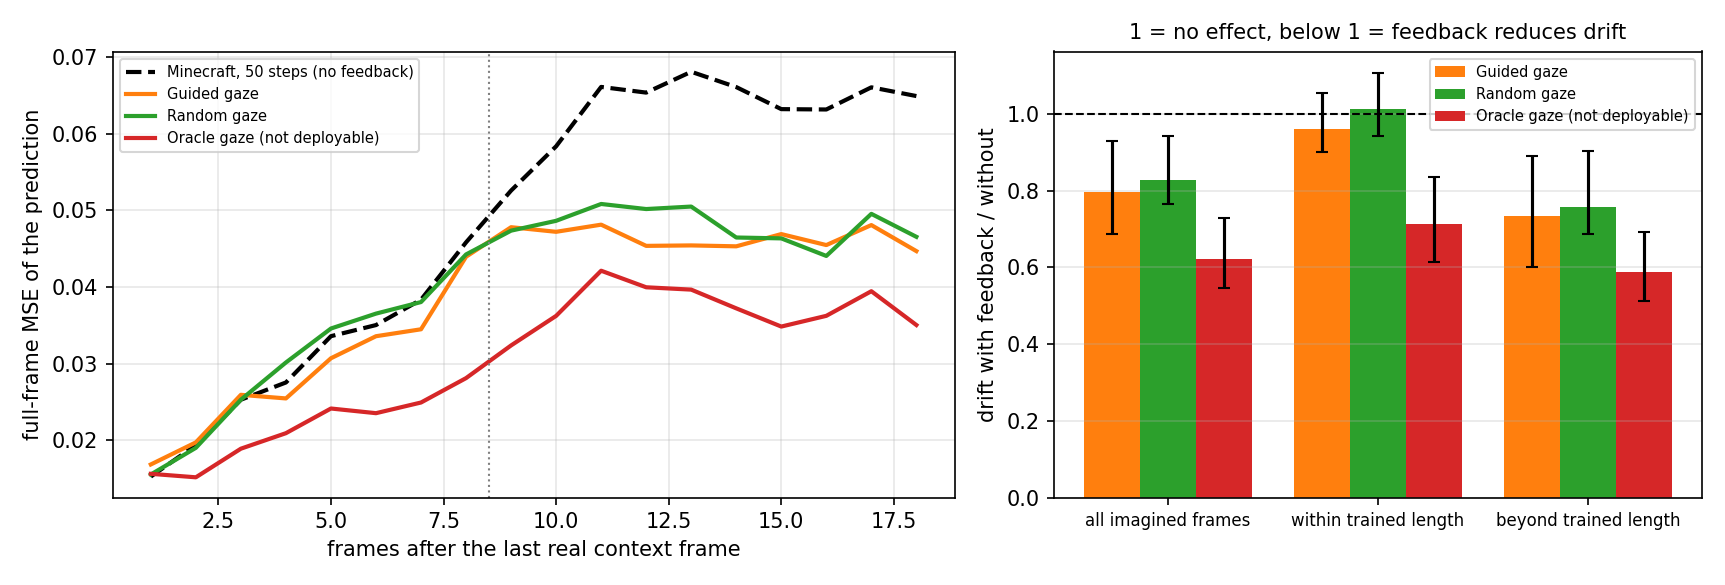

**Figure 9. The clip with the median improvement under guided gaze**

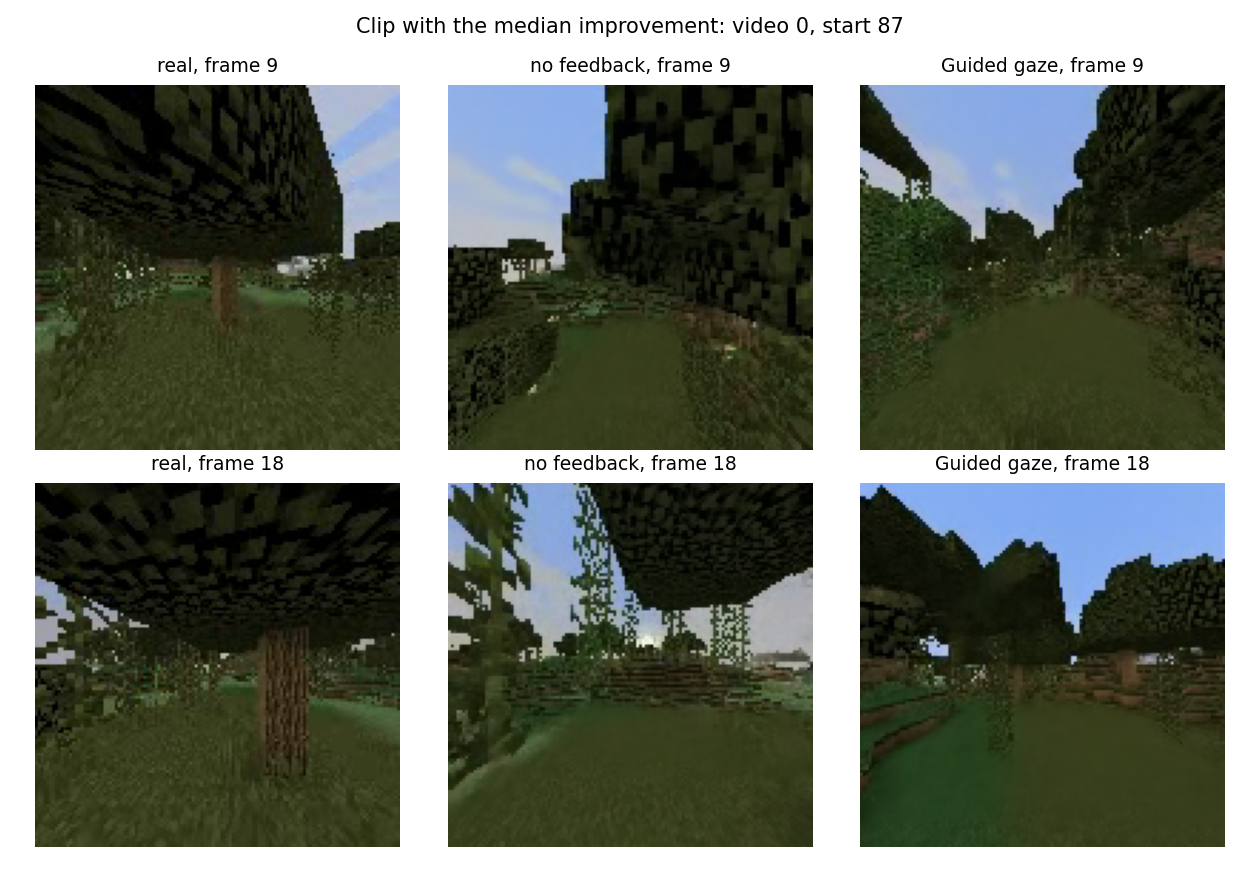

In [13]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RESULTS}/feedback.md").read()))
display(Markdown("**Figure 8. Drift with and without one real patch per frame fed back into the model**"))
display(Image(filename=f"{RESULTS}/fig8_feedback.png", width=900))
display(Markdown("**Figure 9. The clip with the median improvement under guided gaze**"))
display(Image(filename=f"{RESULTS}/fig9_feedback_example.png", width=700))

## 8. Export

In [14]:
shutil.copytree(LOGS, f"{RESULTS}/generation_logs", dirs_exist_ok=True)
shutil.copy(AUDIT, RESULTS)
shutil.copy(f"{REPO}/df_feedback_run.py", RESULTS)
shutil.copy(f"{DUMP_ROOT}/plan.json", RESULTS)
archive = shutil.make_archive(f"{WORK}/wm_audit_feedback_results", "zip", RESULTS)
size = sum(os.path.getsize(f) for f in glob.glob(f"{DUMP_ROOT}/**/*.npz", recursive=True)) / 2**20
print("results:", archive)
print(f"raw rollouts kept in: {DUMP_ROOT} ({size:.0f} MB)")
print(f"total notebook time: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")

results: /kaggle/working/wm_audit_feedback_results.zip
raw rollouts kept in: /kaggle/working/wm_audit_data (452 MB)
total notebook time: 3.57 h
